In [2]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import string
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from textblob import TextBlob
from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from nltk.util import ngrams
import gensim
from gensim.models import Phrases
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from collections import Counter
import seaborn as sns
from collections import Counter






In [3]:
# Percorso del file CSV con le recensioni
file_path = 'data/Amazon_Reviews_inglese.csv' 

# Carica il file CSV
df = pd.read_csv(file_path)

# Mostra le prime righe del dataframe per capire la struttura dei dati
print(df.head())

# Rimuovi le recensioni duplicate basate sulla colonna 'Review text'
df_cleaned = df.drop_duplicates(subset=['Review text'])

# Elimina le colonne 'Helpful count', 'Badges', 'Top Contributor'
df_cleaned = df_cleaned.drop(columns=['Helpful count', 'Badges', 'Top Contributor'])

# Salva il dataframe pulito in un nuovo file CSV
cleaned_file_path = 'data/cleaned_Amazon_Reviews_inglese.csv'  # Stringa grezza per evitare problemi con le backslash
df_cleaned.to_csv(cleaned_file_path, index=False)

# Verifica il numero di recensioni prima e dopo la rimozione dei duplicati
print(f"Numero di recensioni originali: {len(df)}")
print(f"Numero di recensioni dopo la rimozione dei duplicati: {len(df_cleaned)}")

In [4]:
# Carica il file pulito 
cleaned_file_path = 'data/cleaned_Amazon_Reviews_inglese.csv'
df_cleaned = pd.read_csv(cleaned_file_path)

# Controlla la presenza di NaN in tutto il DataFrame
nan_counts = df_cleaned.isnull().sum()
print(nan_counts)

# Rimuovi le righe con NaN nella colonna 'Review text'
df_cleaned = df_cleaned.dropna(subset=['Review text'])

In [5]:
# Carica il file pulito CSV
cleaned_file_path = 'data/cleaned_Amazon_Reviews_inglese.csv'
df_cleaned = pd.read_csv(cleaned_file_path)


# Trova le righe in cui 'Review text' non è di tipo stringa
non_string_values = df_cleaned[~df_cleaned['Review text'].apply(lambda x: isinstance(x, str))]

df_cleaned = df_cleaned.drop(index=326)

# Mostra le righe con valori non stringa
print(non_string_values)


In [6]:
# Conta quanti valori non stringa ci sono nella colonna 'Review text'
non_string_count = df_cleaned['Review text'].apply(lambda x: not isinstance(x, str)).sum()

print(f"Numero di valori non stringa nella colonna 'Review text': {non_string_count}")


Numero di valori non stringa nella colonna 'Review text': 0


In [7]:
# Elimina righe con valori non stringa nella colonna 'Review text'
df_cleaned = df_cleaned.dropna(subset=['Review text'])


# Definisci il percorso del nuovo file CSV
new_file_path = 'data/new_cleaned_Amazon_Reviews_inglese_2.csv'

# Salva il DataFrame modificato in un nuovo file CSV
df_cleaned.to_csv(new_file_path, index=False)


In [8]:
# Scarica le risorse necessarie di nltk
nltk.download('punkt')
nltk.download('stopwords')

# Carica il file pulito CSV
cleaned_file_path = 'data/new_cleaned_Amazon_Reviews_inglese_2.csv'
df_cleaned = pd.read_csv(cleaned_file_path)

# Inizializza la lista di stopwords
stop_words = set(stopwords.words('english'))
stop_words.add("’")
# Funzione di pre-elaborazione del testo
def preprocess_text(text):
    # Converti in minuscolo
    text = text.lower()
    # Rimuovi la punteggiatura
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenizza il testo
    words = word_tokenize(text)
    # Rimuovi stopwords
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

# Applica la pre-elaborazione a ogni recensione
df_cleaned['Processed_Review'] = df_cleaned['Review text'].apply(preprocess_text)

# Mostra le prime righe del dataframe pre-elaborato
print(df_cleaned.head())



In [9]:
#ricontrolla

# Inizializza il vettorizzatore TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)  # Usa 5000 caratteristiche principali

# Trasforma il testo delle recensioni
X = vectorizer.fit_transform(df_cleaned['Processed_Review'])

# Mostra la forma della matrice risultante
print(X.shape)



(418, 2031)


In [10]:

# Inizializza VADER
nltk.download('vader_lexicon')
sid = SentimentIntensityAnalyzer()

# Funzione per ottenere il sentiment con VADER
def get_sentiment_vader(text):
    scores = sid.polarity_scores(text)
    if scores['compound'] >= 0.05:
        return 'positive'
    elif scores['compound'] <= -0.05:
        return 'negative'
    else:
        return 'neutral'

# Applica la funzione di sentiment a ogni recensione
df_cleaned['Sentiment'] = df_cleaned['Processed_Review'].apply(get_sentiment_vader)
# Applica VADER al dataset
df_cleaned['Sentiment_VADER'] = df_cleaned['Processed_Review'].apply(get_sentiment_vader)


# Funzione per ottenere il sentiment con TextBlob
def get_sentiment_textblob(text):
    analysis = TextBlob(text)
    if analysis.sentiment.polarity > 0:
        return 'positive'
    elif analysis.sentiment.polarity < 0:
        return 'negative'
    else:
        return 'neutral'

# Applica TextBlob al dataset
df_cleaned['Sentiment_TextBlob'] = df_cleaned['Processed_Review'].apply(get_sentiment_textblob)

# Inizializza il pipeline di sentiment analysis di BERT
classifier = pipeline('sentiment-analysis')

# Funzione per ottenere il sentiment con BERT
def get_sentiment_bert(text):
    result = classifier(text)[0]
    if result['label'] == 'POSITIVE':
        return 'positive'
    elif result['label'] == 'NEGATIVE':
        return 'negative'
    else:
        return 'neutral'

# Applica BERT al dataset
df_cleaned['Sentiment_BERT'] = df_cleaned['Processed_Review'].apply(get_sentiment_bert)

# Funzione per valutare le prestazioni del modello
def evaluate_performance(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    return accuracy, precision, recall, f1

# Valuta VADER
accuracy_vader, precision_vader, recall_vader, f1_vader = evaluate_performance(df_cleaned['Sentiment'], df_cleaned['Sentiment_VADER'])
print(f"VADER - Accuracy: {accuracy_vader}, Precision: {precision_vader}, Recall: {recall_vader}, F1-score: {f1_vader}")

# Valuta TextBlob
accuracy_textblob, precision_textblob, recall_textblob, f1_textblob = evaluate_performance(df_cleaned['Sentiment'], df_cleaned['Sentiment_TextBlob'])
print(f"TextBlob - Accuracy: {accuracy_textblob}, Precision: {precision_textblob}, Recall: {recall_textblob}, F1-score: {f1_textblob}")

# Valuta BERT
accuracy_bert, precision_bert, recall_bert, f1_bert = evaluate_performance(df_cleaned['Sentiment'], df_cleaned['Sentiment_BERT'])
print(f"BERT - Accuracy: {accuracy_bert}, Precision: {precision_bert}, Recall: {recall_bert}, F1-score: {f1_bert}")


# Creare un DataFrame con i risultati delle valutazioni
results = pd.DataFrame({
    'Model': ['VADER', 'TextBlob', 'BERT'],
    'Accuracy': [accuracy_vader, accuracy_textblob, accuracy_bert],
    'Precision': [precision_vader, precision_textblob, precision_bert],
    'Recall': [recall_vader, recall_textblob, recall_bert],
    'F1-score': [f1_vader, f1_textblob, f1_bert]
})

# mostra DataFrame come tabella
print(results)




VADER - Accuracy: 1.0, Precision: 1.0, Recall: 1.0, F1-score: 1.0
TextBlob - Accuracy: 0.7392344497607656, Precision: 0.7395101247837972, Recall: 0.7392344497607656, F1-score: 0.7386462721122106
BERT - Accuracy: 0.45933014354066987, Precision: 0.44608625823936826, Recall: 0.45933014354066987, F1-score: 0.40660948793647567
      Model  Accuracy  Precision    Recall  F1-score
0     VADER  1.000000   1.000000  1.000000  1.000000
1  TextBlob  0.739234   0.739510  0.739234  0.738646
2      BERT  0.459330   0.446086  0.459330  0.406609


In [11]:


# Applica la funzione di sentiment a ogni recensione
#df_cleaned['Sentiment'] = df_cleaned['Processed_Review'].apply(get_sentiment_vader)


# Mostra le prime righe del dataframe con il sentiment
print(df_cleaned.head())

# Stampa le recensioni con valori non validi
print(df_cleaned[df_cleaned['Processed_Review'].apply(lambda x: isinstance(x, float))]['Processed_Review'])

# Elimina le righe 17 e 271 dal DataFrame
#df_cleaned.drop([17, 271], inplace=True)

# Rimuovi il testo aggiuntivo "out of 5 stars" dalla colonna "stars"
df_cleaned['stars'] = df_cleaned['stars'].str.replace(' out of 5 stars', '')

# Rimuovere il testo duplicato dalla colonna "stars"
df_cleaned['stars'] = df_cleaned['stars'].str.split('|').str[0]

import re

# Funzione per rimuovere pattern come "5.0 out of 5 stars" dai titoli delle recensioni
def clean_review_title(title):
    return re.sub(r'\d+\.\d+ out of \d+ stars\s*', '', title)

# Applica la funzione di pulizia alla colonna "review title"
df_cleaned['review title'] = df_cleaned['review title'].apply(clean_review_title)


# Salva il dataframe con il sentiment in un nuovo file CSV
sentiment_file_path = 'data/sentiment_Amazon_Reviews_inglese.csv'
df_cleaned.to_csv(sentiment_file_path, index=False)



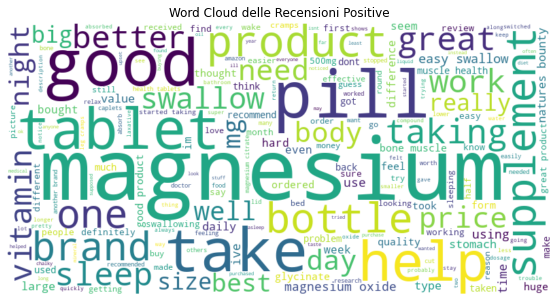

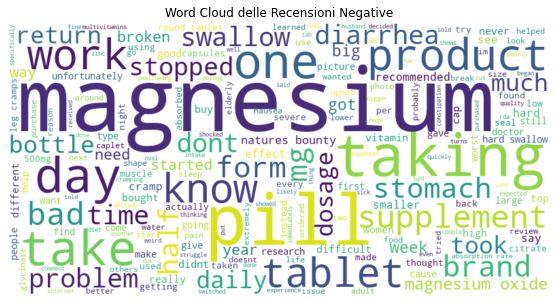

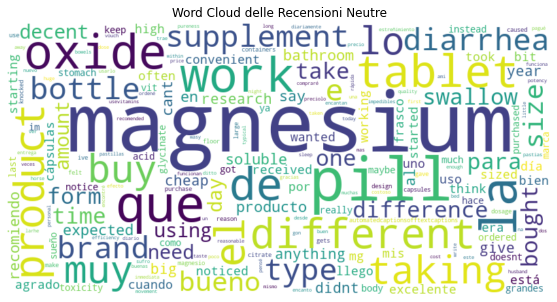

In [12]:

# Crea una stringa contenente tutte le recensioni positive
positive_reviews = ' '.join(df_cleaned[df_cleaned['Sentiment'] == 'positive']['Processed_Review'])


# Crea una WordCloud per le recensioni positive
wordcloud_positive = WordCloud(width=800, height=400, background_color='white').generate(positive_reviews)

# Visualizza la WordCloud per le recensioni positive
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.title('Word Cloud delle Recensioni Positive')
plt.axis('off')
plt.show()

# Crea una stringa contenente tutte le recensioni negative
negative_reviews = ' '.join(df_cleaned[df_cleaned['Sentiment'] == 'negative']['Processed_Review'])

# Crea una WordCloud per le recensioni negative
wordcloud_negative = WordCloud(width=800, height=400, background_color='white').generate(negative_reviews)

# Visualizza la WordCloud per le recensioni negative
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.title('Word Cloud delle Recensioni Negative')
plt.axis('off')
plt.show()

# Crea una stringa contenente tutte le recensioni neutre
neutral_reviews = ' '.join(df_cleaned[df_cleaned['Sentiment'] == 'neutral']['Processed_Review'])

# Crea una WordCloud per le recensioni neutre
wordcloud_neutral = WordCloud(width=800, height=400, background_color='white').generate(neutral_reviews)

# Visualizza la WordCloud per le recensioni neutre
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_neutral, interpolation='bilinear')
plt.title('Word Cloud delle Recensioni Neutre')
plt.axis('off')
plt.show()


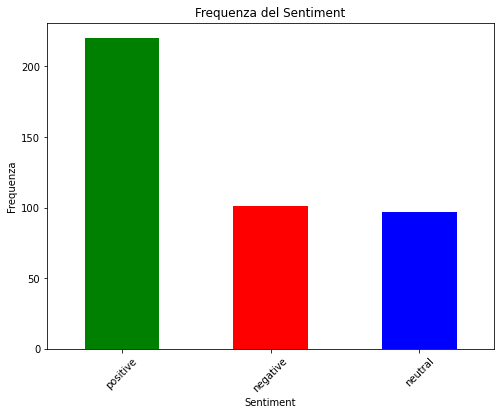

In [13]:

# Calcola le frequenze di ciascuna classe di sentiment
sentiment_counts = df_cleaned['Sentiment'].value_counts()

# Crea il grafico a barre delle frequenze di sentiment
plt.figure(figsize=(8, 6))
sentiment_counts.plot(kind='bar', color=['green', 'red', 'blue'])
plt.title('Frequenza del Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Frequenza')
plt.xticks(rotation=45)
plt.show()



In [14]:

# Calcola le frequenze di ciascuna classe di sentiment
sentiment_counts = df_cleaned['Sentiment'].value_counts()

# Crea un diagramma a torta in 3D della distribuzione delle classi di sentiment
fig = go.Figure(data=[go.Pie(labels=sentiment_counts.index, values=sentiment_counts, hole=0.3)])
fig.update_layout(title='Distribuzione percentuale del Sentiment', scene=dict(aspectmode='auto'))
fig.show()



In [26]:

# Raggruppa le recensioni per punteggio di stella e sentiment
star_sentiment_counts = df_cleaned.groupby(['stars', 'Sentiment']).size().unstack(fill_value=0)

# Crea un oggetto figura Plotly
fig = go.Figure()

# Aggiungi le barre per ciascuna classe di sentiment
for sentiment in star_sentiment_counts.columns:
    fig.add_trace(go.Bar(
        x=star_sentiment_counts.index,
        y=star_sentiment_counts[sentiment],
        name=sentiment,
        marker_color=['red', 'blue', 'green'][list(star_sentiment_counts.columns).index(sentiment)]
    ))

# Aggiungi layout e titoli
fig.update_layout(barmode='stack', title='Recensioni per Stelle e Sentiment', xaxis_title='Punteggio di Stella', yaxis_title='Numero di Recensioni')
fig.show()



In [16]:
# Aggiungi una colonna per la lunghezza delle recensioni
df_cleaned['Review_Length'] = df_cleaned['Processed_Review'].apply(len)

# Crea un diagramma a dispersione 
fig = px.scatter(df_cleaned, x='Review_Length', y='Sentiment', color='Sentiment', 
                 title='Lunghezza delle Recensioni rispetto al Sentiment',
                 labels={'Review_Length': 'Lunghezza della Recensione', 'Sentiment': 'Sentiment'})
fig.update_traces(marker=dict(size=8))
fig.show()


In [25]:
# Lista di stopwords personalizzate
custom_stopwords = {'que','de', 'el', 'la', 'y', 'en', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para', 'con', 'una', 'su', 'al', 'es', 'lo', 'como', 'más', 'pero', 'sus', 'le', 'ya', 'o', 'fue', 'ha', 'sí', 'porque', 'esta', 'son', 'entre', 'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos', 'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 'ese', 'eso', 'ante', 'ellos', 'e', 'esto', 'mí', 'antes', 'algunos', 'qué', 'unos', 'yo', 'otro', 'otras', 'otra', 'él', 'tanto', 'esa', 'estos', 'mucho', 'quienes', 'nada', 'muchos', 'cual', 'poco', 'ella', 'estar', 'estas', 'algunas', 'algo', 'nosotros', 'mi', 'mis', 'tú', 'te', 'ti', 'tu', 'tus', 'ellas', 'nosotras', 'vosotros', 'vosotras', 'os', 'mío', 'mía', 'míos', 'mías', 'tuyo', 'tuya', 'tuyos', 'tuyas', 'suyo', 'suya', 'suyos', 'suyas', 'nuestro', 'nuestra', 'nuestros', 'nuestras', 'vuestro', 'vuestra', 'vuestros', 'vuestras', 'esos', 'esas', 'estoy', 'estás', 'está', 'estamos', 'estáis', 'están', 'esté', 'estés', 'estemos', 'estéis', 'estén', 'estaré', 'estarás', 'estará', 'estaremos', 'estaréis', 'estarán', 'estaría', 'estarías', 'estaríamos', 'estaríais', 'estarían', 'estaba', 'estabas', 'estábamos', 'estabais', 'estaban', 'estuve', 'estuviste', 'estuvo', 'estuvimos', 'estuvisteis', 'estuvieron', 'estuviera', 'estuvieras', 'estuviéramos', 'estuvierais', 'estuvieran', 'estuviese', 'estuvieses', 'estuviésemos', 'estuvieseis', 'estuviesen', 'estando', 'estado', 'estada', 'estados', 'estadas', 'estad'}
additional_stopwords = {'magnesium'}

# Unisci le stopwords personalizzate e quelle aggiuntive
all_stopwords = custom_stopwords.union(additional_stopwords)

# Crea un Counter per le parole per ogni classe di sentiment
positive_words = Counter(' '.join(df_cleaned[df_cleaned['Sentiment'] == 'positive']['Processed_Review']).split())
negative_words = Counter(' '.join(df_cleaned[df_cleaned['Sentiment'] == 'negative']['Processed_Review']).split())
neutral_words = Counter(' '.join(df_cleaned[df_cleaned['Sentiment'] == 'neutral']['Processed_Review']).split())

# Rimuovi le stopwords dai Counter delle parole
positive_words = {word: count for word, count in positive_words.items() if word not in all_stopwords}
negative_words = {word: count for word, count in negative_words.items() if word not in all_stopwords}
neutral_words = {word: count for word, count in neutral_words.items() if word not in all_stopwords}

# Estrai le parole più comuni per ogni classe di sentiment (ad esempio, le prime 15)
top_positive_words = Counter(positive_words).most_common(15)
top_negative_words = Counter(negative_words).most_common(15)
top_neutral_words = Counter(neutral_words).most_common(15)

# Crea un DataFrame per le parole più comuni
df_top_words = pd.DataFrame({
    'Word': [word[0] for word in top_positive_words + top_negative_words + top_neutral_words],
    'Count': [word[1] for word in top_positive_words + top_negative_words + top_neutral_words],
    'Sentiment': ['Positive'] * 15 + ['Negative'] * 15 + ['Neutral'] * 15
})

# Crea il grafico
fig = px.bar(df_top_words, x='Word', y='Count', color='Sentiment', 
             title='Parole più Comuni per Classe di Sentiment', 
             labels={'Word': 'Parola', 'Count': 'Conteggio', 'Sentiment': 'Sentiment'})
fig.show()





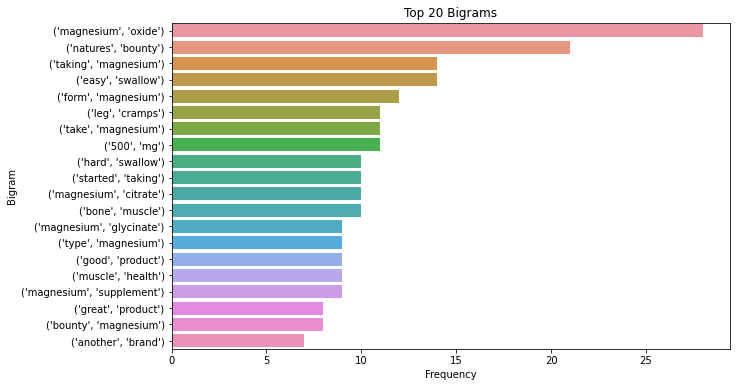

In [18]:
# Funzione per generare bigrammi da una frase
def generate_bigrams(text):
    tokens = text.split()
    return list(ngrams(tokens, 2))

# Applica la funzione a tutte le recensioni
df_cleaned['Bigrams'] = df_cleaned['Processed_Review'].apply(lambda x: generate_bigrams(x))

# Calcola la frequenza dei bigrammi
ngram_freq = df_cleaned['Bigrams'].explode().value_counts().reset_index()
ngram_freq.columns = ['Bigram', 'Frequency']

# Visualizza i primi 20 bigrammi più comuni
plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Bigram', data=ngram_freq.head(20))
plt.title('Top 20 Bigrams')
plt.xlabel('Frequency')
plt.ylabel('Bigram')
plt.show()



In [19]:
# Calcola il conteggio di recensioni per ogni valore di stelle
star_distribution = df_cleaned['stars'].value_counts().sort_index()

# Stampare la distribuzione delle stelle
print("Distribuzione delle Stelle:")
print(star_distribution)



Distribuzione delle Stelle:
stars
1.0    70
2.0    56
3.0    96
4.0    98
5.0    98
Name: count, dtype: int64


In [20]:
import plotly.graph_objs as go

# Creazione del grafico a barre interattivo
fig = go.Figure()
colors =  ('lightgreen')
fig.add_trace(go.Bar(
    x=star_distribution.index,
    y=star_distribution.values,
    marker_color=colors
))

# Aggiunta di titoli e etichette
fig.update_layout(
    title='Distribuzione delle Stelle',
    xaxis=dict(title='Stelle'),
    yaxis=dict(title='Numero di Recensioni')
)

# Mostra il grafico
fig.show()

